In [1]:
######################################################################################################
# ALUNO : Daniel Marques Diniz Maia
# MATRÍCULA : 2026061836
# TURMA : TM
######################################################################################################

In [2]:
#===================================================================
#                        IMPORTANTE
#  Por favor salvem o Jupyter Notebook como ATV04-FulanoDeTal.ipynb, 
#  onde FulanoDeTal é o seu nome completo e postem em nossa sala de
#  aula no MS Teams !


import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit as cf
from scipy.interpolate import interp1d as it1
from scipy.interpolate import CubicSpline
from scipy.signal import savgol_filter

# Definindo o domínio que será usado por todas as funções
x = np.linspace(0,10,15)
xnew = np.linspace(min(x),max(x),105)
def ruido(y):
    return 0.06*(1-2*(np.random.rand(len(y))))


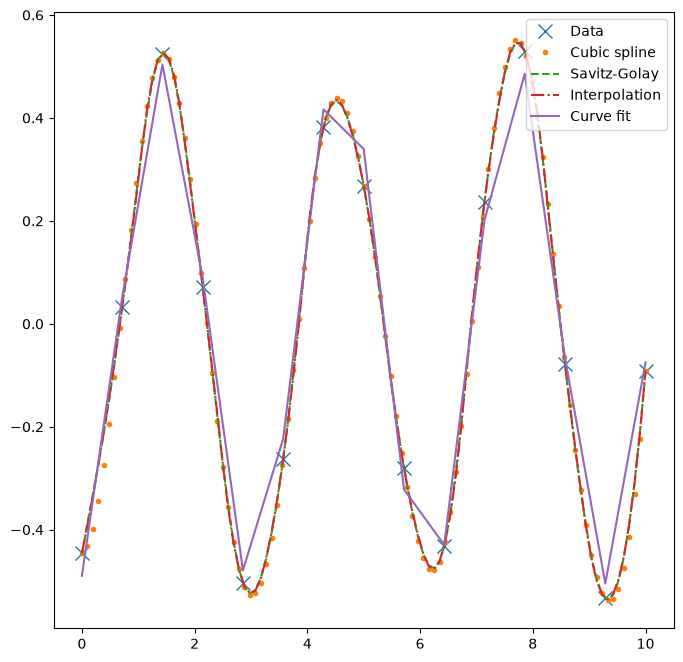

"Nota-se que a diferença entre as interpolações é mínima, embora o ajuste de curva (com um erro relativamente pequeno) não descreve bem a curva.
Além disso, as interpolações neste gráfico não estão muito sujeitas a ruídos, diferentemente de outros gráficos.


In [3]:
# Atividade 1 - Para a função y = a * sin(b*x + c) faça
# (a) gere um conjunto de dados incluindo ruído;
# (b) suavização tipo "cubic spline";
# (c) suavização tipo Savitz Golay;
# (d) interpolação polinomial;
# (e) ajuste de curva;
# (f) faça um gráfico único com todos os dados dos itens (a) até (e)
# (g) faça uma discussão dos resultados;
# Faça a discussão dos resultados


def funcao1(x,a,b,c):
    return a * np.sin(b*x + c)
y1 = funcao1(x,0.5,2,5)
y1 += ruido(y1)
cs1 = CubicSpline(x, y1)
y1_itp = it1(x,y1,kind='quadratic')
y1_smooth = savgol_filter(y1_itp(xnew), window_length=15, polyorder=4)
pars,cov = cf(f=funcao1,xdata=x,ydata=y1,p0=[1,2,4], bounds=[-np.inf,np.inf])
plt.figure(figsize=(8,8))
plt.plot(x, y1, 'x', markersize=10)
plt.plot(xnew, cs1(xnew), '.', xnew,y1_smooth, '--',xnew,y1_itp(xnew), '-.', x, funcao1(x, *pars), '-', )
plt.legend(['Data', 'Cubic spline', "Savitz-Golay", 'Interpolation','Curve fit'])
plt.show()

print(""""Nota-se que a diferença entre as interpolações é mínima, embora o ajuste de curva (com um erro relativamente pequeno) não descreve bem a curva.
Além disso, as interpolações neste gráfico não estão muito sujeitas a ruídos, diferentemente de outros gráficos.""")

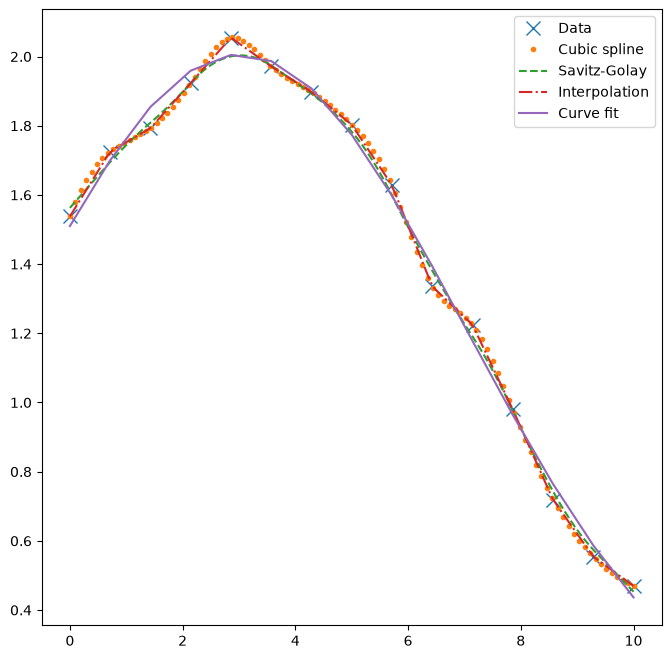

Percebe-se que o ajuste de curva, utilizando parâmetros com o mesmo erro absoluto que o anterior erro em a=0.5, em b=0, em c=1) obteve mais sucesso neste caso.
Também observam-se pequenas flutuações nas interpolações, que são efetivamente suavizadas por Savitz-Golay (mas não por Cubic Spline).
Aqui, as interpolações sofrem uma influência bem maior dos ruídos do que o plot anterior.


In [4]:
# Atividade 2 - Para uma função gaussiana faça
# (a) gere um conjunto de dados incluindo ruído;
# (b) suavização tipo "cubic spline";
# (c) suavização tipo Savitz Golay;
# (d) interpolação polinomial;
# (e) ajuste de curva;
# (f) faça um gráfico único com todos os dados dos itens (a) até (e)
# (g) faça uma discussão dos resultados;
# Faça a discussão dos resultados

def gaussian(x, a, b, c):
    return a*np.exp(-np.power(x - b, 2)/(2*np.power(c, 2)))
y2 = gaussian(x,2,3,4)
y2 += ruido(y2)
cs2 = CubicSpline(x, y2)
y2_itp = it1(x,y2,kind='linear')
y2_smooth = savgol_filter(y2_itp(xnew), window_length=15, polyorder=1)
pars,_ = cf(f=gaussian,xdata=x,ydata=y2,p0=[1.5,3,3], bounds=[-np.inf,np.inf])
plt.figure(figsize=(8,8))
plt.plot(x, y2, 'x', markersize=10)
plt.plot(xnew,cs2(xnew), '.', xnew,y2_smooth, '--',xnew,y2_itp(xnew), '-.', x,gaussian(x,*pars), '-', )
plt.legend(['Data', 'Cubic spline', "Savitz-Golay", 'Interpolation','Curve fit'])
plt.show()

print("""Percebe-se que o ajuste de curva, utilizando parâmetros com o mesmo erro absoluto que o anterior erro em a=0.5, em b=0, em c=1) obteve mais sucesso neste caso.
Também observam-se pequenas flutuações nas interpolações, que são efetivamente suavizadas por Savitz-Golay (mas não por Cubic Spline).
Aqui, as interpolações sofrem uma influência bem maior dos ruídos do que o plot anterior.""")

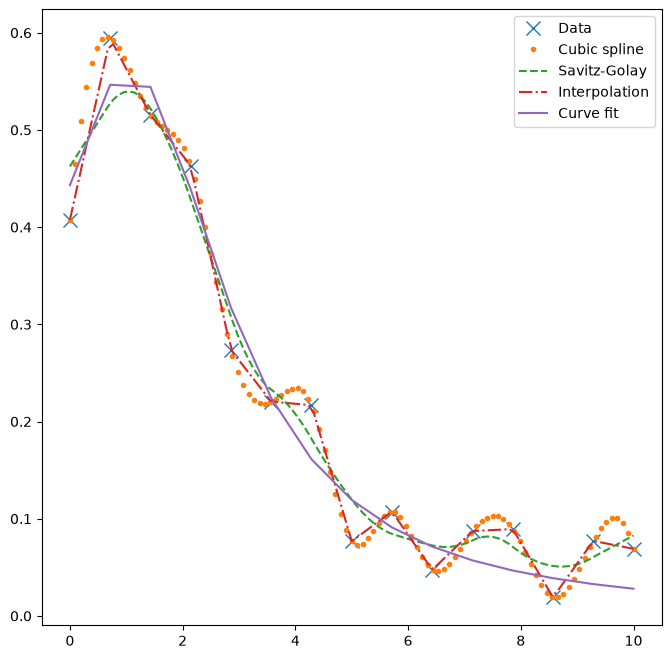

 A interpolação de grau 1 e o CubicSpline obtiveram resultados semelhantes distorcendo a curva esperada, enquanto Savitz-Golay efetivamente suavizou a curva, embora não tenha se aproximado
tanto do ajuste de curva (muito acurado, neste caso).
Como os valores da lorentizana são menores que 1, ela está muito sujeita a ruído, o que explica as inconsistências de cada método utilizado neste gráfico.


In [5]:
# Atividade 3 - Para uma função lorentziana faça
# (a) gere um conjunto de dados incluindo ruído;
# (b) suavização tipo "cubic spline";
# (c) suavização tipo Savitz Golay;
# (d) interpolação polinomial;
# (e) ajuste de curva;
# (f) faça um gráfico único com todos os dados dos itens (a) até (e)
# (g) faça uma discussão dos resultados;
# Faça a discussão dos resultados

def lorentziana(x,a,b,c):
    return a/( (x - b)**2 + c )
y3 = lorentziana(x,2.5,1,4.5)
y3 += ruido(y3)
cs3 = CubicSpline(x,y3)
y3_itp = it1(x,y3,kind='linear')
y3_smooth = savgol_filter(y3_itp(xnew), window_length=15, polyorder=1)
pars,_ = cf(f=lorentziana,xdata=x,ydata=y3,p0=[2,1,5.5], bounds=[-np.inf,np.inf])
plt.figure(figsize=(8,8))
plt.plot(x, y3, 'x', markersize=10)
plt.plot(xnew,cs3(xnew), '.', xnew,y3_smooth, '--',xnew,y3_itp(xnew), '-.', x,lorentziana(x,*pars), '-', )
plt.legend(['Data', 'Cubic spline', "Savitz-Golay", 'Interpolation','Curve fit'])
plt.show()

print(""" A interpolação de grau 1 e o CubicSpline obtiveram resultados semelhantes distorcendo a curva esperada, enquanto Savitz-Golay efetivamente suavizou a curva, embora não tenha se aproximado
tanto do ajuste de curva (muito acurado, neste caso).
Como os valores da lorentizana são menores que 1, ela está muito sujeita a ruído, o que explica as inconsistências de cada método utilizado neste gráfico.""")

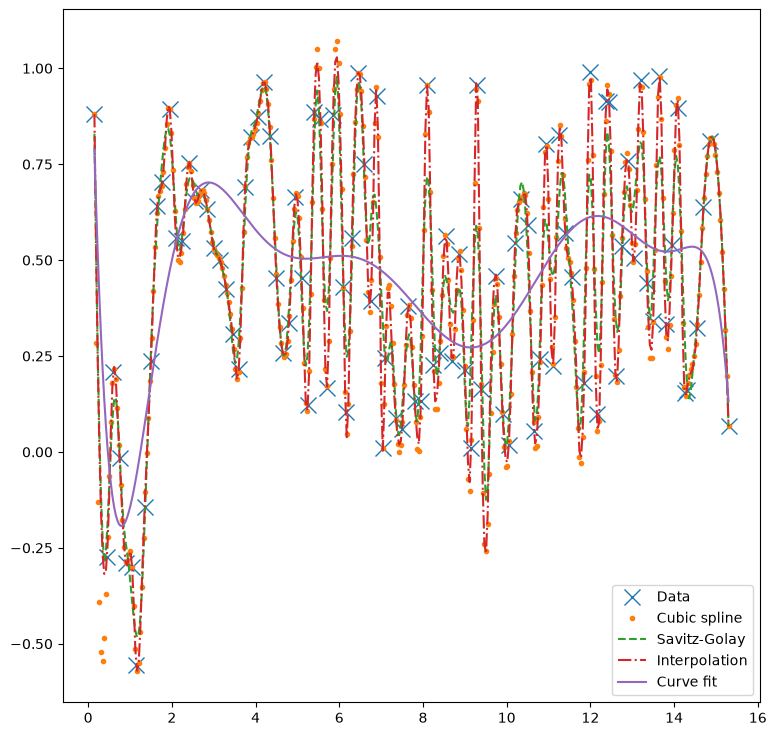

In [6]:
# Atividade 4 - Para o conjunto de dados fornecido abaixo faça:
# (a) leia o conjunto de dados fornecido abaixo;
# (b) suavização tipo "cubic spline";
# (c) suavização tipo Savitz Golay;
# (d) interpolação polinomial;
# (e) ajuste de curva;
# (f) faça um gráfico único com todos os dados dos itens (a) até (e)
# (g) faça uma discussão dos resultados;
# Faça a discussão dos resultados

###############################################################
dados = """0.15000   0.88074
   0.45000  -0.27343
   0.60000   0.20726
   0.75000  -0.01649
   0.90000  -0.28865
   1.05000  -0.29876
   1.15000  -0.55483
   1.35000  -0.14270
   1.50000   0.23730
   1.65000   0.64194
   1.77000   0.70322
   1.95000   0.89408
   2.10000   0.55641
   2.25000   0.54948
   2.40000   0.75237
   2.55000   0.65511
   2.70000   0.68235
   2.85000   0.63281
   3.00000   0.53248
   3.15000   0.50083
   3.30000   0.42535
   3.45000   0.30699
   3.60000   0.21694
   3.75000   0.69009
   3.90000   0.82114
   4.05000   0.87351
   4.20000   0.96497
   4.35000   0.82450
   4.50000   0.45236
   4.65000   0.25863
   4.80000   0.33738
   4.95000   0.66538
   5.10000   0.45252
   5.25000   0.12255
   5.40000   0.88680
   5.55000   0.86841
   5.70000   0.16588
   5.85000   0.87785
   6.10000   0.42957
   6.15000   0.10375
   6.30000   0.55851
   6.45000   0.98703
   6.60000   0.75136
   6.75000   0.39453
   6.90000   0.92825
   7.05000   0.01087
   7.10000   0.24566
   7.35000   0.08873
   7.50000   0.05992
   7.65000   0.38077
   7.80000   0.13342
   7.95000   0.13246
   8.10000   0.95714
   8.25000   0.22580
   8.40000   0.25862
   8.55000   0.56299
   8.70000   0.23621
   8.85000   0.51565
   9.00000   0.21283
   9.15000   0.00997
   9.30000   0.95753
   9.39000   0.16447
   9.75000   0.45849
   9.90000   0.09871
  10.05000   0.01744
  10.20000   0.54524
  10.35000   0.65995
  10.50000   0.59095
  10.65000   0.05585
  10.80000   0.24324
  10.95000   0.80386
  11.10000   0.22294
  11.25000   0.82716
  11.40000   0.57150
  11.55000   0.45607
  11.85000   0.18047
  12.00000   0.99162
  12.15000   0.09803
  12.38000   0.91456
  12.45000   0.91254
  12.60000   0.19791
  12.75000   0.53686
  12.90000   0.75798
  13.05000   0.50550
  13.20000   0.96838
  13.35000   0.44115
  13.50000   0.34072
  13.65000   0.98092
  13.80000   0.33266
  13.95000   0.53988
  14.10000   0.89722
  14.25000   0.15455
  14.30000   0.16139
  14.55000   0.32429
  14.70000   0.63791
  14.85000   0.81178
  15.30000   0.06709
"""

x4,y4 = np.array([float(line.split()[0]) for line in dados.splitlines()]),np.array([float(line.split()[1]) for line in dados.splitlines()])
x4new = np.linspace(min(x4),max(x4),4*len(x4))
coefs = np.polyfit(x4,y4,9)
func4 = np.poly1d(coefs)
cs4 = CubicSpline(x4,y4)
y4_itp = it1(x4,y4, kind="quadratic")
y4_smooth = savgol_filter(y4_itp(x4new),window_length=13, polyorder=2)
plt.figure(figsize=(9,9))
plt.plot(x4, y4, 'x', markersize=12)
plt.plot(x4new,cs4(x4new), '.', x4new,y4_smooth, '--',x4new,y4_itp(x4new), '-.', x4new,func4(x4new),'-')
plt.legend(['Data', 'Cubic spline', "Savitz-Golay", 'Interpolation','Curve fit'])
plt.show()